In [ ]:
#README kinda
# notebooks go from task to resnet18_implementation to resnet_18_tta
# install all dependencies
#when installing torch I used cu118 because i have a gtx 1070ti gpu. 
# %pip install torch torchvision --index-url https://download.pytorch.org/whl/cu118  # or your CUDA version / CPU
# %pip install tqdm scikit-learn pandas pillow matplotlib

In [ ]:
# Run this cell only if required
#%pip install numpy matplotlib scikit-learn
#%pip install pandas

   ---------------------------------------- 0.0/12.6 MB ? eta -:--:--
   ----- ---------------------------------- 1.8/12.6 MB 9.1 MB/s eta 0:00:02
   ------------ --------------------------- 3.9/12.6 MB 10.2 MB/s eta 0:00:01
   ------------------- -------------------- 6.0/12.6 MB 10.3 MB/s eta 0:00:01
   -------------------------- ------------- 8.4/12.6 MB 10.4 MB/s eta 0:00:01
   ---------------------------------- ----- 10.7/12.6 MB 10.8 MB/s eta 0:00:01
   ---------------------------------------- 12.6/12.6 MB 10.4 MB/s eta 0:00:00
   ---------------------------------------- 0.0/9.3 MB ? eta -:--:--
   ---------- ----------------------------- 2.4/9.3 MB 11.2 MB/s eta 0:00:01
   -------------------- ------------------- 4.7/9.3 MB 11.9 MB/s eta 0:00:01
   ------------------------------ --------- 7.1/9.3 MB 11.5 MB/s eta 0:00:01
   ---------------------------------------- 9.3/9.3 MB 11.0 MB/s eta 0:00:00
   ---------------------------------------- 0.0/8.3 MB ? eta -:--:--
   ----------- 


[notice] A new release of pip is available: 25.0.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


   ---------------------------------------- 0.0/9.7 MB ? eta -:--:--
   -------- ------------------------------- 2.1/9.7 MB 10.7 MB/s eta 0:00:01
   ------------------- -------------------- 4.7/9.7 MB 11.4 MB/s eta 0:00:01
   ------------------------------ --------- 7.3/9.7 MB 11.6 MB/s eta 0:00:01
   ---------------------------------------  9.4/9.7 MB 11.7 MB/s eta 0:00:01
   ---------------------------------------- 9.7/9.7 MB 11.1 MB/s eta 0:00:00
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.0.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


=== File & Directory Verification ===
Train directory resolved to: dataset_images\train
Test directory resolved to:  dataset_images\test
train_labels.csv columns:    ['image_id', 'class']
sample_submission.csv columns: ['image_id', 'class']

=== Dataset Summary ===
Total labeled training images in CSV: 63660
Total test images in folder:          29443

=== Number of Images per Class ===
class
CatEye      13884
DogEye      11580
CatNose      6942
CatFace      6942
CatMouth     6942
DogMouth     5790
DogFace      5790
DogNose      5790
Name: count, dtype: int64


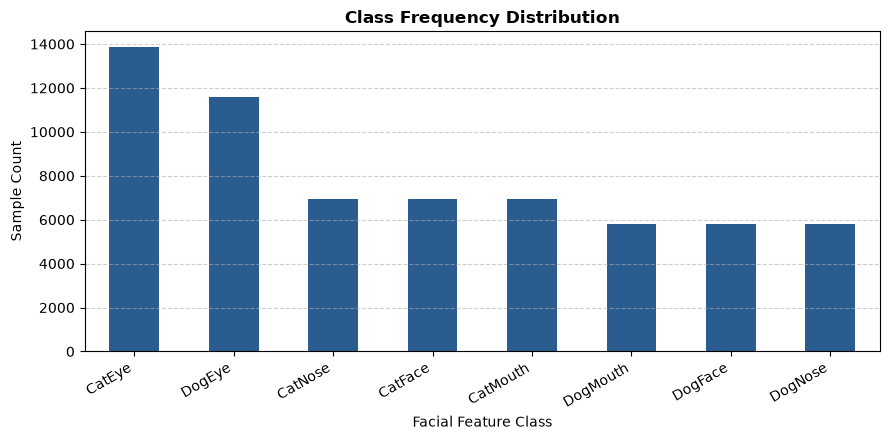

Auditing image files...

=== Image Quality Audit ===
Corrupted or missing images: 0
Smallest image resolution : 4 x 4
Largest image resolution  : 2219 x 2219
Average image resolution  : 113 x 109


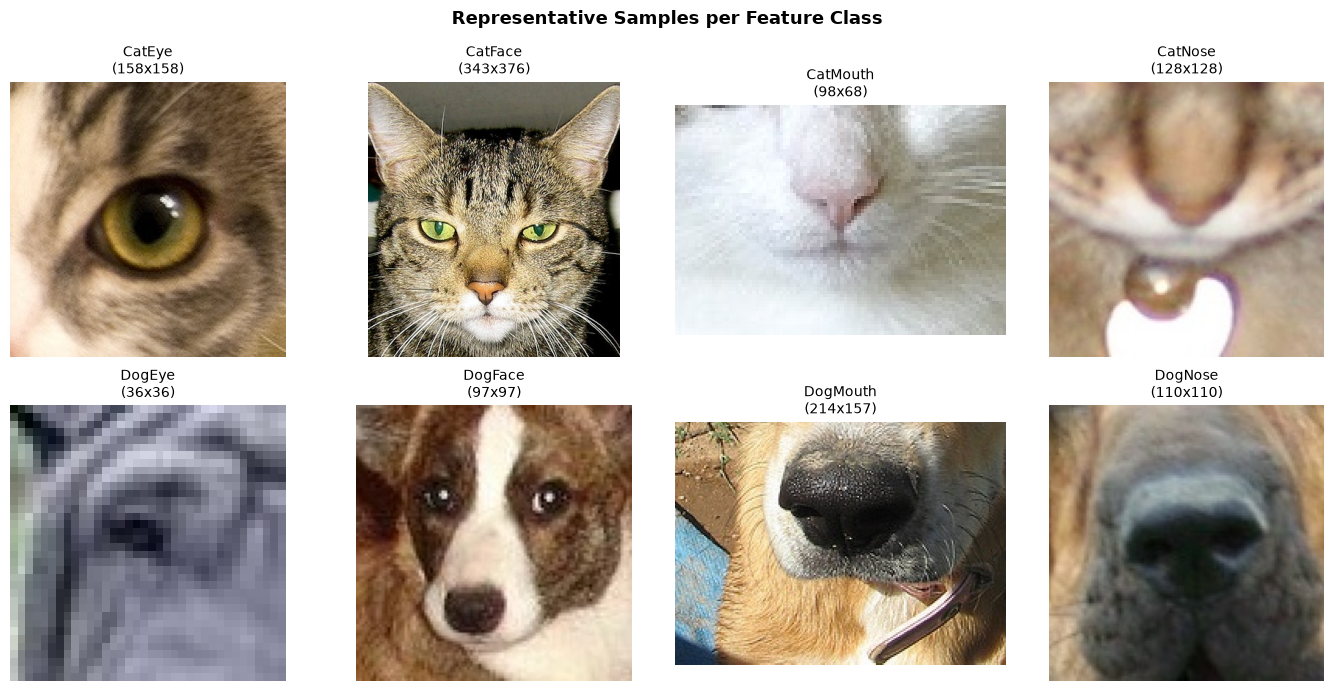

In [1]:
import os
import glob
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

# -------------------------------------------------------------------------
# 1. Directory & File Paths (configured for dataset_images)
# -------------------------------------------------------------------------
TRAIN_LABELS_CSV = "train_labels.csv"
SAMPLE_SUB_CSV = "sample_submission.csv"

# Automatically resolve the correct folder location
if os.path.exists(os.path.join("dataset_images", "train")):
    TRAIN_IMG_DIR = os.path.join("dataset_images", "train")
    TEST_IMG_DIR = os.path.join("dataset_images", "test")
elif os.path.exists(os.path.join("train", "train")):
    TRAIN_IMG_DIR = os.path.join("train", "train")
    TEST_IMG_DIR = os.path.join("test", "test")
else:
    TRAIN_IMG_DIR = "train"
    TEST_IMG_DIR = "test"

# -------------------------------------------------------------------------
# 2. Inspect CSV headers and structure (dtype=str keeps leading zeros)
# -------------------------------------------------------------------------
df = pd.read_csv(TRAIN_LABELS_CSV, dtype=str)
sample_sub = pd.read_csv(SAMPLE_SUB_CSV, dtype=str)

print("=== File & Directory Verification ===")
print(f"Train directory resolved to: {TRAIN_IMG_DIR}")
print(f"Test directory resolved to:  {TEST_IMG_DIR}")
print(f"train_labels.csv columns:    {df.columns.tolist()}")
print(f"sample_submission.csv columns: {sample_sub.columns.tolist()}\n")

id_col = "image_id" if "image_id" in df.columns else df.columns[0]
target_col = "class" if "class" in df.columns else df.columns[1]

print("=== Dataset Summary ===")
print(f"Total labeled training images in CSV: {len(df)}")
test_files = os.listdir(TEST_IMG_DIR)
print(f"Total test images in folder:          {len(test_files)}\n")

# Helper function to find images with or without 5-digit padding
def resolve_image_path(folder, raw_id):
    raw_str = str(raw_id).strip()
    base, ext = os.path.splitext(raw_str)
    ext = ext if ext else ".jpg"
    
    # Try 5-digit zero-padding first (e.g., '9322' -> '09322.jpg')
    base_padded = base.zfill(5) if base.isdigit() else base
    path_padded = os.path.join(folder, f"{base_padded}{ext}")
    if os.path.exists(path_padded):
        return path_padded
        
    # Fallback to unpadded
    path_raw = os.path.join(folder, f"{base}{ext}")
    if os.path.exists(path_raw):
        return path_raw
        
    return path_padded  # Default target if missing

# -------------------------------------------------------------------------
# 3. Class Counts and Distribution
# -------------------------------------------------------------------------
print("=== Number of Images per Class ===")
class_counts = df[target_col].value_counts()
print(class_counts)

# Visualise and save class balance
plt.figure(figsize=(9, 4.5))
class_counts.plot(kind="bar", color="#2b5c8f")
plt.title("Class Frequency Distribution", fontsize=12, fontweight="bold")
plt.xlabel("Facial Feature Class")
plt.ylabel("Sample Count")
plt.xticks(rotation=30, ha="right")
plt.grid(axis="y", linestyle="--", alpha=0.6)
plt.tight_layout()
plt.savefig("class_distribution.png", dpi=300)
plt.show()

# -------------------------------------------------------------------------
# 4. Check for Corruptions, Image Sizes & Extensions
# -------------------------------------------------------------------------
widths, heights = [], []
corrupt_images = []

print("Auditing image files...")
for raw_id in df[id_col]:
    img_path = resolve_image_path(TRAIN_IMG_DIR, raw_id)

    try:
        with Image.open(img_path) as img:
            w, h = img.size
            widths.append(w)
            heights.append(h)
    except Exception as e:
        corrupt_images.append((img_path, str(e)))

print("\n=== Image Quality Audit ===")
print(f"Corrupted or missing images: {len(corrupt_images)}")
if corrupt_images:
    print(f"First 3 missing examples: {corrupt_images[:3]}")

if widths and heights:
    print(f"Smallest image resolution : {min(widths)} x {min(heights)}")
    print(f"Largest image resolution  : {max(widths)} x {max(heights)}")
    print(f"Average image resolution  : {sum(widths)//len(widths)} x {sum(heights)//len(heights)}")

# -------------------------------------------------------------------------
# 5. Visualise 1 Sample Image per Class
# -------------------------------------------------------------------------
unique_classes = sorted(df[target_col].unique())
fig, axes = plt.subplots(2, 4, figsize=(14, 7))
axes = axes.flatten()

for i, cls_name in enumerate(unique_classes):
    sample_id = df[df[target_col] == cls_name][id_col].iloc[0]
    sample_path = resolve_image_path(TRAIN_IMG_DIR, sample_id)
    
    img = Image.open(sample_path)
    
    axes[i].imshow(img)
    axes[i].set_title(f"{cls_name}\n({img.size[0]}x{img.size[1]})", fontsize=10)
    axes[i].axis("off")

plt.suptitle("Representative Samples per Feature Class", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.savefig("sample_classes.png", dpi=300)
plt.show()